In [ ]:
# Fix for Google Colab's missing tfds dependency
!pip install importlib_resources -q

import os
import gc
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, backend as K
import tensorflow_datasets as tfds

# Create required directories
PLOTS_DIR = 'plots'
RESULTS_DIR = 'results'
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
global_metrics = {}
model_histories = {}

print("--- DOWNLOADING AND PREPARING TF_FLOWERS ---")
dataset, info = tfds.load('tf_flowers', with_info=True, as_supervised=True,
                          split=['train[:70%]', 'train[70%:85%]', 'train[85%:]'])
train_raw, val_raw, test_raw = dataset
num_classes = info.features['label'].num_classes
class_names = info.features['label'].names

# ImageNet Preprocessing & Augmentation Pipeline
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1)
], name="data_augmentation")

def preprocess_train(image, label):
    image = tf.image.resize(image, (224, 224))
    image = tf.keras.applications.resnet50.preprocess_input(image)
    return image, label

def preprocess_test(image, label):
    image = tf.image.resize(image, (224, 224))
    image = tf.keras.applications.resnet50.preprocess_input(image)
    return image, label

BATCH_SIZE = 32
train_ds = train_raw.map(preprocess_train).batch(BATCH_SIZE).map(lambda x, y: (data_augmentation(x, training=True), y)).prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.map(preprocess_test).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_raw.map(preprocess_test).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Caching test set for evaluation...")
X_test, y_test = [], []
for imgs, lbls in test_ds:
    X_test.append(imgs.numpy())
    y_test.append(lbls.numpy())
X_test = np.concatenate(X_test, axis=0)
y_test = np.concatenate(y_test, axis=0)

print(f"Classes: {class_names}")
print(f"Train/Val/Test batches: {len(train_ds)} / {len(val_ds)} / {len(test_ds)}")
print("Cell 1 Complete. Dataset prepared.")

--- DOWNLOADING AND PREPARING TF_FLOWERS ---


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.AEOY5G_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Caching test set for evaluation...
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Train/Val/Test batches: 81 / 18 / 18
Cell 1 Complete. Dataset prepared.


In [ ]:
print("\n--- DEFINING KERAS-3 SAFE ATTENTION MECHANISMS ---")

def channel_attention(x, reduction=16, name=''):
    channels = x.shape[-1]
    z = layers.GlobalAveragePooling2D(name=f'{name}_ca_gap')(x)
    z = layers.Dense(channels // reduction, activation='relu', use_bias=False, name=f'{name}_ca_dense1')(z)
    z = layers.Dense(channels, activation='sigmoid', use_bias=False, name=f'{name}_ca_dense2')(z)
    z = layers.Reshape((1, 1, channels), name=f'{name}_ca_reshape')(z)
    return layers.Multiply(name=f'{name}_ca_mul')([x, z]), z

def spatial_attention(x, kernel_size=7, name=''):
    # Wrapped in Lambda to prevent KerasTensor math errors
    avg_pool = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True), name=f'{name}_sa_avg')(x)
    max_pool = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True), name=f'{name}_sa_max')(x)
    concat = layers.Concatenate(axis=-1, name=f'{name}_sa_concat')([avg_pool, max_pool])
    attn = layers.Conv2D(1, kernel_size, activation='sigmoid', padding='same', use_bias=False, name=f'{name}_sa_conv')(concat)
    return layers.Multiply(name=f'{name}_sa_mul')([x, attn]), attn

def self_attention(x, name=''):
    channels = x.shape[-1]
    q = layers.Conv2D(channels//8, 1, name=f'{name}_sa_q')(x)
    k = layers.Conv2D(channels//8, 1, name=f'{name}_sa_k')(x)
    v = layers.Conv2D(channels, 1, name=f'{name}_sa_v')(x)

    def apply_self_attn(tensors):
        q_t, k_t, v_t, orig_x = tensors
        shape = tf.shape(orig_x)
        B, H, W = shape[0], shape[1], shape[2]
        q_flat = tf.reshape(q_t, [-1, H*W, channels//8])
        k_flat = tf.reshape(k_t, [-1, H*W, channels//8])
        v_flat = tf.reshape(v_t, [-1, H*W, channels])
        attn = tf.matmul(q_flat, k_flat, transpose_b=True)
        attn = tf.nn.softmax(attn)
        out = tf.matmul(attn, v_flat)
        out = tf.reshape(out, [-1, H, W, channels])
        return out

    out = layers.Lambda(apply_self_attn, name=f'{name}_sa_lambda')([q, k, v, x])

    class ScaleLayer(layers.Layer):
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
        def build(self, input_shape):
            self.gamma = self.add_weight(name=f'{name}_sa_gamma', shape=(), initializer='zeros', trainable=True)
        def call(self, inputs):
            orig_x, attn_out = inputs
            return orig_x + self.gamma * attn_out

    out = ScaleLayer(name=f'{name}_sa_scale')([x, out])
    return out, q

def apply_attn(x, type_name, pos_name):
    if type_name == 'channel': x, _ = channel_attention(x, name=pos_name)
    elif type_name == 'spatial': x, _ = spatial_attention(x, name=pos_name)
    elif type_name == 'channel_spatial':
        x, _ = channel_attention(x, name=pos_name)
        x, _ = spatial_attention(x, name=pos_name)
    elif type_name == 'self': x, _ = self_attention(x, name=pos_name)
    return x

print("--- BUILDING MODULAR RESNET50 & EXTRACTING WEIGHTS INTO RAM ---")
# Bypass disk-saving bugs completely by keeping weights in a dictionary
base_model = tf.keras.applications.ResNet50(include_top=False, weights='imagenet')
BASE_WEIGHTS = {layer.name: layer.get_weights() for layer in base_model.layers if layer.get_weights()}
del base_model
gc.collect()

def resnet_block(x, filters, kernel_size=3, stride=1, conv_shortcut=True, name=None):
    bn_axis = 3
    if conv_shortcut:
        shortcut = layers.Conv2D(4 * filters, 1, strides=stride, name=name + '_0_conv')(x)
        shortcut = layers.BatchNormalization(axis=bn_axis, epsilon=1.001e-5, name=name + '_0_bn')(shortcut)
    else:
        shortcut = x
    x = layers.Conv2D(filters, 1, strides=stride, name=name + '_1_conv')(x)
    x = layers.BatchNormalization(axis=bn_axis, epsilon=1.001e-5, name=name + '_1_bn')(x)
    x = layers.Activation('relu', name=name + '_1_relu')(x)
    x = layers.Conv2D(filters, kernel_size, padding='SAME', name=name + '_2_conv')(x)
    x = layers.BatchNormalization(axis=bn_axis, epsilon=1.001e-5, name=name + '_2_bn')(x)
    x = layers.Activation('relu', name=name + '_2_relu')(x)
    x = layers.Conv2D(4 * filters, 1, name=name + '_3_conv')(x)
    x = layers.BatchNormalization(axis=bn_axis, epsilon=1.001e-5, name=name + '_3_bn')(x)
    x = layers.Add(name=name + '_add')([shortcut, x])
    x = layers.Activation('relu', name=name + '_out')(x)
    return x

def build_attention_resnet(attn_config=None):
    if attn_config is None: attn_config = {}

    img_input = layers.Input(shape=(224, 224, 3))
    x = layers.Conv2D(64, 7, strides=2, padding='same', name='conv1_conv')(img_input)
    x = layers.BatchNormalization(axis=3, epsilon=1.001e-5, name='conv1_bn')(x)
    x = layers.Activation('relu', name='conv1_relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same', name='pool1_pool')(x)

    x = resnet_block(x, 64, stride=1, conv_shortcut=True, name='conv2_block1')
    x = resnet_block(x, 64, conv_shortcut=False, name='conv2_block2')
    x = resnet_block(x, 64, conv_shortcut=False, name='conv2_block3')

    x = resnet_block(x, 128, stride=2, conv_shortcut=True, name='conv3_block1')
    x = resnet_block(x, 128, conv_shortcut=False, name='conv3_block2')
    x = resnet_block(x, 128, conv_shortcut=False, name='conv3_block3')
    x = resnet_block(x, 128, conv_shortcut=False, name='conv3_block4')
    if 'P2' in attn_config: x = apply_attn(x, attn_config['P2'], 'P2')

    x = resnet_block(x, 256, stride=2, conv_shortcut=True, name='conv4_block1')
    for i in range(2, 7): x = resnet_block(x, 256, conv_shortcut=False, name=f'conv4_block{i}')
    if 'P3' in attn_config: x = apply_attn(x, attn_config['P3'], 'P3')

    x = resnet_block(x, 512, stride=2, conv_shortcut=True, name='conv5_block1')
    x = resnet_block(x, 512, conv_shortcut=False, name='conv5_block2')
    x = resnet_block(x, 512, conv_shortcut=False, name='conv5_block3')
    if 'P4' in attn_config: x = apply_attn(x, attn_config['P4'], 'P4')

    x = layers.GlobalAveragePooling2D(name='final_gap')(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(5, activation='softmax', name='predictions')(x)

    model = models.Model(img_input, out)
    for layer in model.layers:
        if layer.name in BASE_WEIGHTS:
            layer.set_weights(BASE_WEIGHTS[layer.name])

    return model

print("Cell 2 Complete. Modules established and weights mapped successfully.")


--- DEFINING KERAS-3 SAFE ATTENTION MECHANISMS ---
--- BUILDING MODULAR RESNET50 & EXTRACTING WEIGHTS INTO RAM ---
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Cell 2 Complete. Modules established and weights mapped successfully.


In [ ]:
print("\n--- 3.1 Training Model: A0_Baseline ---")
EPOCHS_FROZEN = 5
EPOCHS_UNFROZEN = 5

exp_name = 'A0_Baseline'
K.clear_session()
model = build_attention_resnet({})

# Freeze Pretrained Backbone (Train Head + Attention first)
for layer in model.layers:
    if not layer.name.startswith(('attn_', 'predictions', 'final_gap')): layer.trainable = False
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_f = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=0)

# Unfreeze Stage 4 and Stage 5 for Fine-Tuning
for layer in model.layers:
    if layer.name.startswith(('conv4', 'conv5')): layer.trainable = True
model.compile(optimizer=optimizers.Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_u = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_UNFROZEN, verbose=0)

model_histories[exp_name] = {'acc': hist_f.history['accuracy'] + hist_u.history['accuracy'], 'val_acc': hist_f.history['val_accuracy'] + hist_u.history['val_accuracy'], 'loss': hist_f.history['loss'] + hist_u.history['loss'], 'val_loss': hist_f.history['val_loss'] + hist_u.history['val_loss']}

inf_start = time.time()
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
global_metrics[exp_name] = {'Acc': accuracy_score(y_test, y_pred)*100, 'Prec': precision_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Rec': recall_score(y_test, y_pred, average='macro', zero_division=0)*100, 'F1': f1_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Params': model.count_params(), 'InfTime': ((time.time() - inf_start) / len(X_test))*1000, 'CM': confusion_matrix(y_test, y_pred)}

# Save Baseline model for Qualitative Analysis later
model.save(f'{exp_name}.keras')
del model
gc.collect()
print(f"{exp_name} Complete.")


--- 3.1 Training Model: A0_Baseline ---
A0_Baseline Complete.


In [ ]:
print("\n--- 3.2 Training Model: A1_Channel_P3 ---")
exp_name = 'A1_Channel_P3'
K.clear_session()
model = build_attention_resnet({'P3': 'channel'})

for layer in model.layers:
    if not layer.name.startswith(('attn_', 'predictions', 'final_gap', 'P3_ca')): layer.trainable = False
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_f = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=0)

for layer in model.layers:
    if layer.name.startswith(('conv4', 'conv5')): layer.trainable = True
model.compile(optimizer=optimizers.Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_u = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_UNFROZEN, verbose=0)

model_histories[exp_name] = {'acc': hist_f.history['accuracy'] + hist_u.history['accuracy'], 'val_acc': hist_f.history['val_accuracy'] + hist_u.history['val_accuracy'], 'loss': hist_f.history['loss'] + hist_u.history['loss'], 'val_loss': hist_f.history['val_loss'] + hist_u.history['val_loss']}

inf_start = time.time()
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
global_metrics[exp_name] = {'Acc': accuracy_score(y_test, y_pred)*100, 'Prec': precision_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Rec': recall_score(y_test, y_pred, average='macro', zero_division=0)*100, 'F1': f1_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Params': model.count_params(), 'InfTime': ((time.time() - inf_start) / len(X_test))*1000, 'CM': confusion_matrix(y_test, y_pred)}

del model
gc.collect()
print(f"{exp_name} Complete.")


--- 3.2 Training Model: A1_Channel_P3 ---
A1_Channel_P3 Complete.


In [ ]:
print("\n--- 3.3 Training Model: A2_Spatial_P3 ---")
exp_name = 'A2_Spatial_P3'
K.clear_session()
model = build_attention_resnet({'P3': 'spatial'})

for layer in model.layers:
    if not layer.name.startswith(('attn_', 'predictions', 'final_gap', 'P3_sa')): layer.trainable = False
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_f = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=0)

for layer in model.layers:
    if layer.name.startswith(('conv4', 'conv5')): layer.trainable = True
model.compile(optimizer=optimizers.Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_u = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_UNFROZEN, verbose=0)

model_histories[exp_name] = {'acc': hist_f.history['accuracy'] + hist_u.history['accuracy'], 'val_acc': hist_f.history['val_accuracy'] + hist_u.history['val_accuracy'], 'loss': hist_f.history['loss'] + hist_u.history['loss'], 'val_loss': hist_f.history['val_loss'] + hist_u.history['val_loss']}

inf_start = time.time()
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
global_metrics[exp_name] = {'Acc': accuracy_score(y_test, y_pred)*100, 'Prec': precision_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Rec': recall_score(y_test, y_pred, average='macro', zero_division=0)*100, 'F1': f1_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Params': model.count_params(), 'InfTime': ((time.time() - inf_start) / len(X_test))*1000, 'CM': confusion_matrix(y_test, y_pred)}

del model
gc.collect()
print(f"{exp_name} Complete.")


--- 3.3 Training Model: A2_Spatial_P3 ---
A2_Spatial_P3 Complete.


In [ ]:
print("\n--- 3.4 Training Model: A3_ChanSpat_P3 ---")
exp_name = 'A3_ChanSpat_P3'
K.clear_session()
model = build_attention_resnet({'P3': 'channel_spatial'})

for layer in model.layers:
    if not layer.name.startswith(('attn_', 'predictions', 'final_gap', 'P3_ca', 'P3_sa')): layer.trainable = False
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_f = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=0)

for layer in model.layers:
    if layer.name.startswith(('conv4', 'conv5')): layer.trainable = True
model.compile(optimizer=optimizers.Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_u = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_UNFROZEN, verbose=0)

model_histories[exp_name] = {'acc': hist_f.history['accuracy'] + hist_u.history['accuracy'], 'val_acc': hist_f.history['val_accuracy'] + hist_u.history['val_accuracy'], 'loss': hist_f.history['loss'] + hist_u.history['loss'], 'val_loss': hist_f.history['val_loss'] + hist_u.history['val_loss']}

inf_start = time.time()
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
global_metrics[exp_name] = {'Acc': accuracy_score(y_test, y_pred)*100, 'Prec': precision_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Rec': recall_score(y_test, y_pred, average='macro', zero_division=0)*100, 'F1': f1_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Params': model.count_params(), 'InfTime': ((time.time() - inf_start) / len(X_test))*1000, 'CM': confusion_matrix(y_test, y_pred)}

# Save this specific model for Qualitative Analysis later
model.save(f'{exp_name}.keras')
del model
gc.collect()
print(f"{exp_name} Complete.")


--- 3.4 Training Model: A3_ChanSpat_P3 ---
A3_ChanSpat_P3 Complete.


In [ ]:
print("\n--- 3.5 Training Model: A4_ChanSpat_P2 ---")
exp_name = 'A4_ChanSpat_P2'
K.clear_session()
model = build_attention_resnet({'P2': 'channel_spatial'})

for layer in model.layers:
    if not layer.name.startswith(('attn_', 'predictions', 'final_gap', 'P2_ca', 'P2_sa')): layer.trainable = False
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_f = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=0)

for layer in model.layers:
    if layer.name.startswith(('conv4', 'conv5')): layer.trainable = True
model.compile(optimizer=optimizers.Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_u = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_UNFROZEN, verbose=0)

model_histories[exp_name] = {'acc': hist_f.history['accuracy'] + hist_u.history['accuracy'], 'val_acc': hist_f.history['val_accuracy'] + hist_u.history['val_accuracy'], 'loss': hist_f.history['loss'] + hist_u.history['loss'], 'val_loss': hist_f.history['val_loss'] + hist_u.history['val_loss']}

inf_start = time.time()
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
global_metrics[exp_name] = {'Acc': accuracy_score(y_test, y_pred)*100, 'Prec': precision_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Rec': recall_score(y_test, y_pred, average='macro', zero_division=0)*100, 'F1': f1_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Params': model.count_params(), 'InfTime': ((time.time() - inf_start) / len(X_test))*1000, 'CM': confusion_matrix(y_test, y_pred)}

del model
gc.collect()
print(f"{exp_name} Complete.")


--- 3.5 Training Model: A4_ChanSpat_P2 ---
A4_ChanSpat_P2 Complete.


In [ ]:
print("\n--- 3.6 Training Model: A5_ChanSpat_P4 ---")
exp_name = 'A5_ChanSpat_P4'
K.clear_session()
model = build_attention_resnet({'P4': 'channel_spatial'})

for layer in model.layers:
    if not layer.name.startswith(('attn_', 'predictions', 'final_gap', 'P4_ca', 'P4_sa')): layer.trainable = False
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_f = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=0)

for layer in model.layers:
    if layer.name.startswith(('conv4', 'conv5')): layer.trainable = True
model.compile(optimizer=optimizers.Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_u = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_UNFROZEN, verbose=0)

model_histories[exp_name] = {'acc': hist_f.history['accuracy'] + hist_u.history['accuracy'], 'val_acc': hist_f.history['val_accuracy'] + hist_u.history['val_accuracy'], 'loss': hist_f.history['loss'] + hist_u.history['loss'], 'val_loss': hist_f.history['val_loss'] + hist_u.history['val_loss']}

inf_start = time.time()
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
global_metrics[exp_name] = {'Acc': accuracy_score(y_test, y_pred)*100, 'Prec': precision_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Rec': recall_score(y_test, y_pred, average='macro', zero_division=0)*100, 'F1': f1_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Params': model.count_params(), 'InfTime': ((time.time() - inf_start) / len(X_test))*1000, 'CM': confusion_matrix(y_test, y_pred)}

del model
gc.collect()
print(f"{exp_name} Complete.")


--- 3.6 Training Model: A5_ChanSpat_P4 ---
A5_ChanSpat_P4 Complete.


In [ ]:
print("\n--- 3.7 Training Model: A6_SelfAttn_P3 ---")
exp_name = 'A6_SelfAttn_P3'
K.clear_session()
model = build_attention_resnet({'P3': 'self'})

for layer in model.layers:
    if not layer.name.startswith(('attn_', 'predictions', 'final_gap', 'P3_sa')): layer.trainable = False
model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_f = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=0)

for layer in model.layers:
    if layer.name.startswith(('conv4', 'conv5')): layer.trainable = True
model.compile(optimizer=optimizers.Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_u = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_UNFROZEN, verbose=0)

model_histories[exp_name] = {'acc': hist_f.history['accuracy'] + hist_u.history['accuracy'], 'val_acc': hist_f.history['val_accuracy'] + hist_u.history['val_accuracy'], 'loss': hist_f.history['loss'] + hist_u.history['loss'], 'val_loss': hist_f.history['val_loss'] + hist_u.history['val_loss']}

inf_start = time.time()
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
global_metrics[exp_name] = {'Acc': accuracy_score(y_test, y_pred)*100, 'Prec': precision_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Rec': recall_score(y_test, y_pred, average='macro', zero_division=0)*100, 'F1': f1_score(y_test, y_pred, average='macro', zero_division=0)*100, 'Params': model.count_params(), 'InfTime': ((time.time() - inf_start) / len(X_test))*1000, 'CM': confusion_matrix(y_test, y_pred)}

del model
gc.collect()
print(f"{exp_name} Complete. All ablations finished.")


--- 3.7 Training Model: A6_SelfAttn_P3 ---
A6_SelfAttn_P3 Complete. All ablations finished.



--- GENERATING QUANTITATIVE PLOTS ---


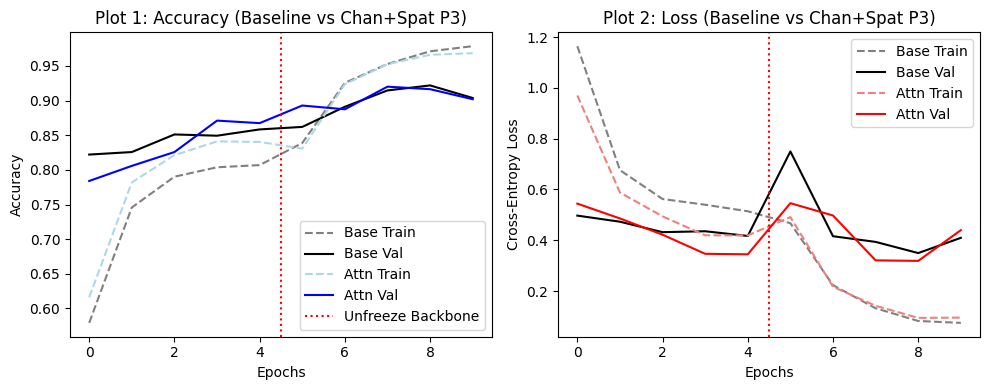

/tmp/ipykernel_2840/3837226262.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=acc_vals, y=names, palette="Blues_d")
/tmp/ipykernel_2840/3837226262.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=f1_vals, y=names, palette="Reds_d")


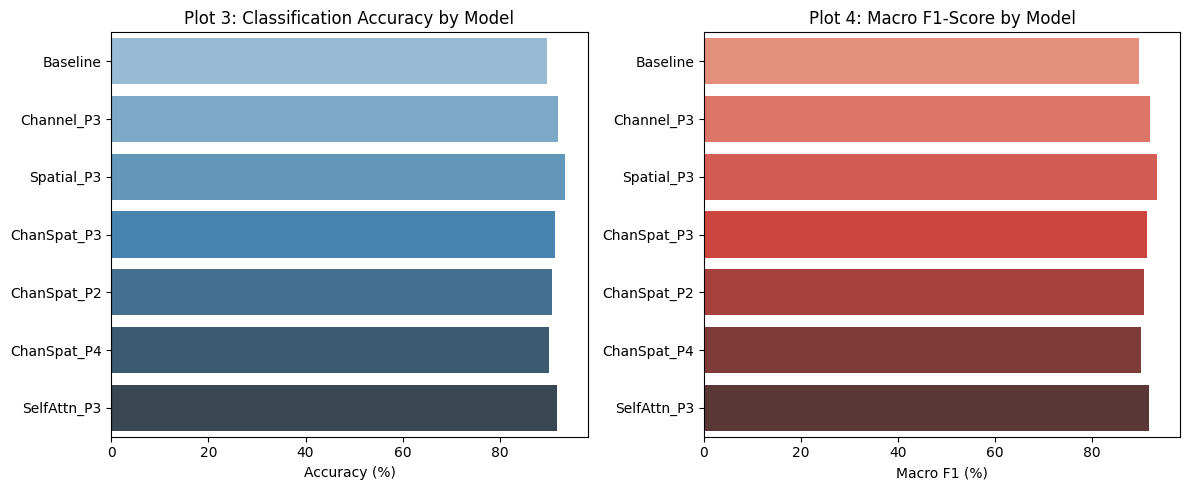

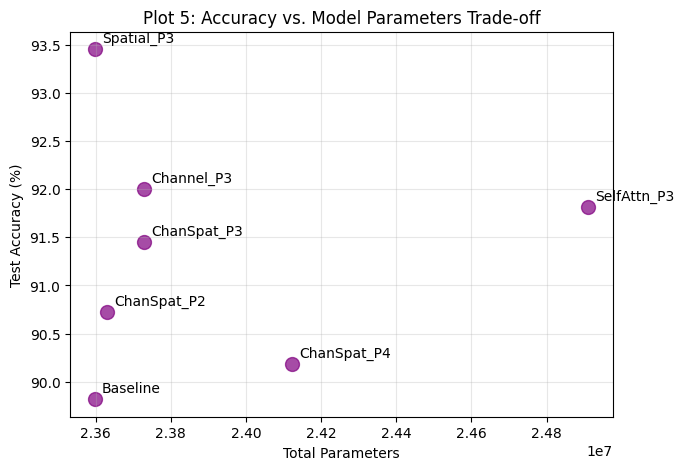

In [ ]:
  print("\n--- GENERATING QUANTITATIVE PLOTS ---")

# Plot 1: Train & Val Accuracy (Baseline vs Best Attention)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(model_histories['A0_Baseline']['acc'], label='Base Train', color='gray', linestyle='--')
plt.plot(model_histories['A0_Baseline']['val_acc'], label='Base Val', color='black')
plt.plot(model_histories['A3_ChanSpat_P3']['acc'], label='Attn Train', color='lightblue', linestyle='--')
plt.plot(model_histories['A3_ChanSpat_P3']['val_acc'], label='Attn Val', color='blue')
plt.axvline(x=4.5, color='red', linestyle=':', label='Unfreeze Backbone')
plt.title("Plot 1: Accuracy (Baseline vs Chan+Spat P3)")
plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.legend()

# Plot 2: Train & Val Loss
plt.subplot(1, 2, 2)
plt.plot(model_histories['A0_Baseline']['loss'], label='Base Train', color='gray', linestyle='--')
plt.plot(model_histories['A0_Baseline']['val_loss'], label='Base Val', color='black')
plt.plot(model_histories['A3_ChanSpat_P3']['loss'], label='Attn Train', color='lightcoral', linestyle='--')
plt.plot(model_histories['A3_ChanSpat_P3']['val_loss'], label='Attn Val', color='red')
plt.axvline(x=4.5, color='red', linestyle=':')
plt.title("Plot 2: Loss (Baseline vs Chan+Spat P3)")
plt.xlabel("Epochs"); plt.ylabel("Cross-Entropy Loss"); plt.legend()
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/Plot_01_02_Curves.png")
plt.show()

# Re-define the experiment keys since we split the training cells
exp_keys = [
    'A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3',
    'A3_ChanSpat_P3', 'A4_ChanSpat_P2', 'A5_ChanSpat_P4', 'A6_SelfAttn_P3'
]

# Plot 3 & 4: Bar Charts (Accuracy and Macro F1)
names = [k.split('_', 1)[1] for k in exp_keys]
acc_vals = [global_metrics[k]['Acc'] for k in exp_keys]
f1_vals = [global_metrics[k]['F1'] for k in exp_keys]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.barplot(x=acc_vals, y=names, palette="Blues_d")
plt.title("Plot 3: Classification Accuracy by Model")
plt.xlabel("Accuracy (%)")

plt.subplot(1, 2, 2)
sns.barplot(x=f1_vals, y=names, palette="Reds_d")
plt.title("Plot 4: Macro F1-Score by Model")
plt.xlabel("Macro F1 (%)")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/Plot_03_04_BarCharts.png")
plt.show()

# Plot 5: Accuracy vs Parameters Trade-off
params = [global_metrics[k]['Params'] for k in exp_keys]
plt.figure(figsize=(7, 5))
plt.scatter(params, acc_vals, color='purple', s=100, alpha=0.7)
for i, txt in enumerate(names):
    plt.annotate(txt, (params[i], acc_vals[i]), xytext=(5, 5), textcoords='offset points')
plt.title("Plot 5: Accuracy vs. Model Parameters Trade-off")
plt.xlabel("Total Parameters")
plt.ylabel("Test Accuracy (%)")
plt.grid(True, alpha=0.3)
plt.savefig(f"{PLOTS_DIR}/Plot_05_Tradeoff.png")
plt.show()


--- GENERATING QUALITATIVE PLOTS (GRAD-CAM & MAPS) ---
Rebuilding architectures and injecting weights...
Models loaded successfully!


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_176']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


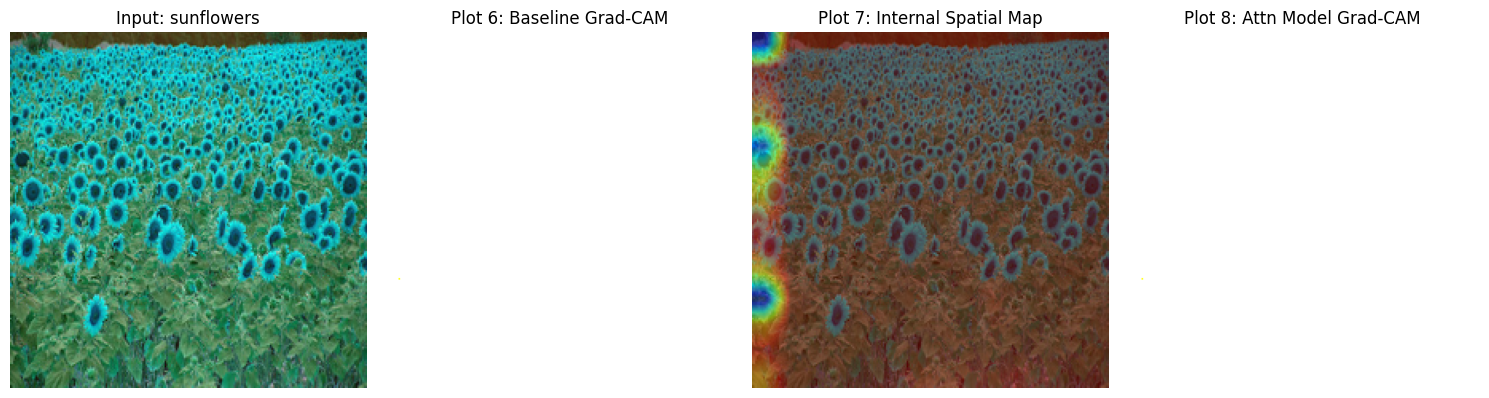

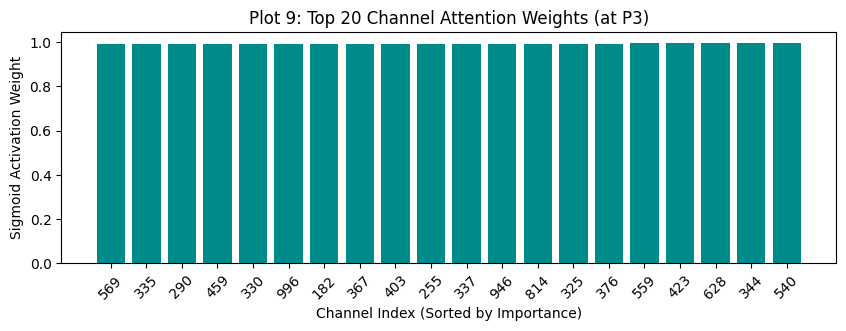

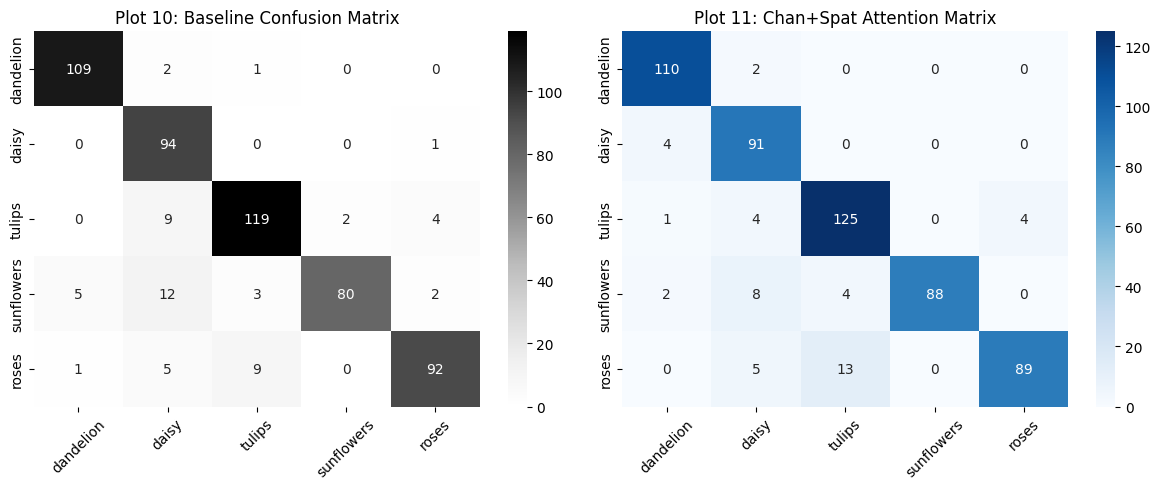

In [ ]:
print("\n--- GENERATING QUALITATIVE PLOTS (GRAD-CAM & MAPS) ---")
K.clear_session()

# =========================================================================
# THE BYPASS: We rebuild the graph natively in Python and ONLY load the weights.
# This completely avoids the Keras 3 Lambda deserialization bug.
# =========================================================================
print("Rebuilding architectures and injecting weights...")
base_model = build_attention_resnet({})
base_model.load_weights('A0_Baseline.keras')

attn_model = build_attention_resnet({'P3': 'channel_spatial'})
attn_model.load_weights('A3_ChanSpat_P3.keras')
print("Models loaded successfully!")
# =========================================================================

test_img = X_test[20] # Representative image
test_img_batch = np.expand_dims(test_img, axis=0)
true_label = class_names[y_test[20]]

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model([model.inputs], [model.get_layer(last_conv_layer_name).output, model.output])
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None: pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]
    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img, heatmap, ax, title):
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    superimposed_img = heatmap * 0.4 + np.uint8(255 * (img - img.min()) / (img.max() - img.min()))
    ax.imshow(np.clip(superimposed_img, 0, 255))
    ax.set_title(title); ax.axis('off')

# Generate Heatmaps
heatmap_base = make_gradcam_heatmap(test_img_batch, base_model, 'conv5_block3_out')
heatmap_attn = make_gradcam_heatmap(test_img_batch, attn_model, 'conv5_block3_out')

# Extract Internal Attention Maps from P3
spatial_extractor = tf.keras.models.Model(inputs=attn_model.input, outputs=attn_model.get_layer('P3_sa_conv').output)
spatial_map = spatial_extractor.predict(test_img_batch, verbose=0)[0, :, :, 0]

channel_extractor = tf.keras.models.Model(inputs=attn_model.input, outputs=attn_model.get_layer('P3_ca_dense2').output)
channel_weights = channel_extractor.predict(test_img_batch, verbose=0).flatten()

# Plot 6 & 7: Grad-CAM Comparison & Spatial Attention Overlay
plt.figure(figsize=(15, 4))
ax1 = plt.subplot(1, 4, 1)
plt.imshow(np.uint8(255 * (test_img - test_img.min()) / (test_img.max() - test_img.min()))); plt.title(f"Input: {true_label}"); plt.axis('off')
ax2 = plt.subplot(1, 4, 2)
display_gradcam(test_img, heatmap_base, ax2, "Plot 6: Baseline Grad-CAM")
ax3 = plt.subplot(1, 4, 3)
sp_map_resized = cv2.resize(spatial_map, (224, 224))
ax3.imshow(np.uint8(255 * (test_img - test_img.min()) / (test_img.max() - test_img.min())))
ax3.imshow(sp_map_resized, cmap='jet', alpha=0.5); ax3.set_title("Plot 7: Internal Spatial Map"); ax3.axis('off')
ax4 = plt.subplot(1, 4, 4)
display_gradcam(test_img, heatmap_attn, ax4, "Plot 8: Attn Model Grad-CAM")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/Plot_06_08_GradCAM.png")
plt.show()

# Plot 9: Internal Channel Weights
plt.figure(figsize=(10, 3))
top_k = np.argsort(channel_weights)[-20:]
plt.bar(range(20), channel_weights[top_k], color='darkcyan')
plt.title("Plot 9: Top 20 Channel Attention Weights (at P3)")
plt.xlabel("Channel Index (Sorted by Importance)"); plt.ylabel("Sigmoid Activation Weight")
plt.xticks(range(20), top_k, rotation=45)
plt.savefig(f"{PLOTS_DIR}/Plot_09_ChannelWeights.png")
plt.show()

# Plot 10 & 11: Confusion Matrices
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.heatmap(global_metrics['A0_Baseline']['CM'], annot=True, fmt='d', cmap='Greys', xticklabels=class_names, yticklabels=class_names)
plt.title("Plot 10: Baseline Confusion Matrix")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.heatmap(global_metrics['A3_ChanSpat_P3']['CM'], annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Plot 11: Chan+Spat Attention Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/Plot_10_11_CM.png")
plt.show()

In [ ]:
import shutil
from google.colab import files

print("\n--- EXPORTING TABLES TO RESULTS DIRECTORY ---")
with open(os.path.join(RESULTS_DIR, 'Experiment_9_Results.txt'), 'w') as f:
    f.write("=== REQUIRED MAIN RESULT TABLE (Section 23) ===\n")
    f.write(f"{'Model':<20} | {'Position':<10} | {'Acc':<8} | {'Prec':<8} | {'Rec':<8} | {'F1':<8} | {'Params':<10} | {'Time(ms)':<10}\n")
    f.write("-" * 95 + "\n")

    display_map = {
        'A0_Baseline': ('Baseline', '-'),
        'A1_Channel_P3': ('Channel', 'P3'),
        'A2_Spatial_P3': ('Spatial', 'P3'),
        'A4_ChanSpat_P2': ('Chan+Spat', 'P2'),
        'A3_ChanSpat_P3': ('Chan+Spat', 'P3'),
        'A5_ChanSpat_P4': ('Chan+Spat', 'P4'),
        'A6_SelfAttn_P3': ('Self-Attn', 'P3')
    }

    for key, (mod, pos) in display_map.items():
        data = global_metrics[key]
        f.write(f"{mod:<20} | {pos:<10} | {data['Acc']:<8.2f} | {data['Prec']:<8.2f} | {data['Rec']:<8.2f} | {data['F1']:<8.2f} | {data['Params']:<10} | {data['InfTime']:<10.2f}\n")

# Zip and Download
shutil.make_archive('Exp9_Attention_Plots', 'zip', PLOTS_DIR)
shutil.make_archive('Exp9_Attention_Results', 'zip', RESULTS_DIR)
files.download('Exp9_Attention_Plots.zip')
files.download('Exp9_Attention_Results.zip')

print("Success! All models trained, plots generated, and results exported.")


--- EXPORTING TABLES TO RESULTS DIRECTORY ---


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Success! All models trained, plots generated, and results exported.
